# Init:

In [2]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json
import asyncio
import numpy as np
import nest_asyncio
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

nest_asyncio.apply()

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

# 1. Load datasets:
Load all three source datasets and structure them as question-answer pairs.

In [78]:
from knowledge_maze.create_dataset.load_datasets import *

# Load all the input datasets, insert destanation path if saving is required.
tqa_dataset = load_tqa(f"{REPO_PATH}\data_files\extracted_nq.json")
nq_dataset = load_nq(f"{REPO_PATH}\data_files\extracted_squad.json")
sqd_dataset = load_sqd(f"{REPO_PATH}\data_files\extracted_triviaQA.json")

total_pairs = len(tqa_dataset) + len(nq_dataset) + len(sqd_dataset)
print(f'Loaded {total_pairs} question-answer pairs in total.')

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\Daniel\\Desktop\\Thesis_Experiment\\QA_Datasets\\trivia_qa_train.json'

In [434]:
# Load from saved dataset:
tqa_dataset = load_json(f"{REPO_PATH}\data_files\extracted_nq.json")
nq_dataset = load_json(f"{REPO_PATH}\data_files\extracted_squad.json")
sqd_dataset = load_json(f"{REPO_PATH}\data_files\extracted_triviaQA.json")

# 2. Classify answers:
Classify answers by types - Wikipedia entities, numbers, dates and free-form.
We will merge all the candidate datasets and discard the free-form answer, also normalize the answers for easier comparison later.

In [3]:
from knowledge_maze.create_dataset.answer_classification import classify_dataset_answers

print('Processing TriviaQA:')
tqa_answer_types = await classify_dataset_answers(tqa_dataset, output_path=f"{REPO_PATH}\data_files\\tqa_answer_types.json")
print('Processing Natural Questions:')
nq_answer_types = await classify_dataset_answers(nq_dataset, output_path=f"{REPO_PATH}\data_files\\nq_answer_types.json")
print('Processing SQuAD:')
sqd_answer_types = await classify_dataset_answers(sqd_dataset, output_path=f"{REPO_PATH}\data_files\\sqd_answer_types.json")

Processing TriviaQA:


Classifying Answers: 100%|██████████████████████████████████████████████████████| 78260/78260 [03:16<00:00, 398.08it/s]


Processing Natural Questions:


Classifying Answers: 100%|████████████████████████████████████████████████████| 106926/106926 [04:22<00:00, 407.29it/s]


Processing SQuAD:


Classifying Answers: 100%|██████████████████████████████████████████████████████| 86821/86821 [03:09<00:00, 459.15it/s]


In [11]:
# Load from saved dataset:
tqa_answer_types = load_json(f"{REPO_PATH}\data_files\\tqa_answer_types.json")
nq_answer_types = load_json(f"{REPO_PATH}\data_files\\nq_answer_types.json")
sqd_answer_types = load_json(f"{REPO_PATH}\data_files\\sqd_answer_types.json")

Merged dataset contains 209055 Q-A pairs out of original 272007(77%).


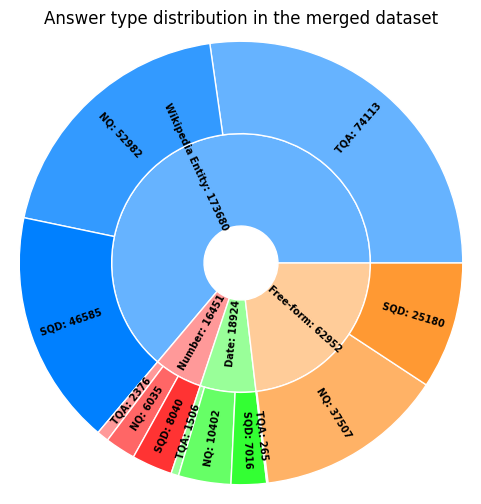

In [4]:
# Merge datasets and visualize results:
from knowledge_maze.create_dataset.answer_classification import merge_datasets

merged_dataset = merge_datasets({
                                     'TQA': tqa_answer_types,
                                     'NQ': nq_answer_types,
                                     'SQD': sqd_answer_types
                                },
                                output_path=f"{REPO_PATH}\data_files\\merged_dataset.json",
                                verbose=True)

In [10]:
# Print exapmles:
from random import choices

for sample in choices(merged_dataset, k=10):
    print(f"Question: {sample['Question']}")
    print(f"Answer: {sample['Answer']}")
    print(f"Type: {sample['Answer type']}")
    print(f"Normalized: {sample['Normalized answer']}")
    print(f"=" * 50)

Question: when did snow white and the seven dwarfs come out
Answer: 1937
Type: Date
Normalized: {'category': 'year', 'parsed_value': '1937'}
Question: What city in Rhode Island is famous for its many mansions built during the late 1800's?
Answer: Newport
Type: Wikipedia Entity
Normalized: Newport
Question: Erik the Red from Norway founded the first successful Norse settlement on Greenland, and then his son Leif continued the tradition of exploring west and landed where?
Answer: North America
Type: Wikipedia Entity
Normalized: North America
Question: What royal park shares a border with its neighbor, the park known as Kensington Gardens?
Answer: Hyde Park
Type: Wikipedia Entity
Normalized: Hyde Park
Question: How many earthquakes occurred on March 5, 2012?
Answer: twelve
Type: Number
Normalized: 12
Question: The Battle of Flodden took place in September 1513 in which English county?
Answer: Northumberland
Type: Wikipedia Entity
Normalized: Northumberland
Question: who won second place i

# 3. Group questions:

In [12]:
# Load from saved dataset:
merged_dataset = load_json(f"{REPO_PATH}\data_files\\merged_dataset.json")

In [13]:
import matplotlib.pyplot as plt
%matplotlib inline
from tqdm import tqdm
from knowledge_maze.create_dataset.cluster_questions import *

In [14]:
# Divide by answer type:
ent_data = []
num_data = []
date_data = []
for sample in merged_dataset:
    if sample['Answer type'] == 'Wikipedia Entity':
        ent_data.append(sample)
    elif sample['Answer type'] == 'Number':
        num_data.append(sample)
    else:
        date_data.append(sample)

In [15]:
# Cluster question by answer:
ent_clusters = cluster_wiki_entities(ent_data)
num_clusters = cluster_numerical_values(num_data)
date_clusters = cluster_date_values(date_data)
print(f'Total candidate clusters:')
print(f'Entities: {len(ent_clusters)} with mean cluster size of: {np.mean([len(value) for value in ent_clusters.values()]):.2f}')
print(f'Numerical: {len(num_clusters)} with mean cluster size of: {np.mean([len(value) for value in num_clusters.values()]):.2f}')
print(f'Date & Time: {len(date_clusters)} with mean cluster size of: {np.mean([len(value) for value in date_clusters.values()]):.2f}')

Total candidate clusters:
Entities: 13337 with mean cluster size of: 6.90
Numerical: 17 with mean cluster size of: 688.18
Date & Time: 960 with mean cluster size of: 19.18


## 3.1 - Cluster and filter entity questions:

In [397]:
from knowledge_maze.create_dataset.create_reasoning_path import create_paths
entity_reasoning_chains = await create_paths(ent_clusters, output_path=f"{REPO_PATH}\data_files\\entity_reasoning_chains.json")

Generating question embeddings: 100%|██████████████████████████████████████████████████| 45/45 [01:50<00:00,  2.45s/it]
Creating similarity graphs and filtering questions: 100%|██████████████████████| 13337/13337 [00:09<00:00, 1334.68it/s]
Splitting large clusters: 100%|██████████████████████████████████████████████| 13337/13337 [00:00<00:00, 835765.14it/s]


In [214]:
# Load from folder:
entity_reasoning_chains = load_json(f"{REPO_PATH}\data_files\\entity_reasoning_chains.json")

## 3.2 - Create numerical questions reasoning paths:

In [429]:
from knowledge_maze.create_dataset.create_reasoning_path import create_paths
numerical_reasoning_chains = await create_paths(num_clusters, output_path=f"{REPO_PATH}\data_files\\numerical_reasoning_chains.json")

Generating question embeddings: 100%|████████████████████████████████████████████████████| 6/6 [00:14<00:00,  2.42s/it]
Creating similarity graphs and filtering questions: 100%|██████████████████████████████| 18/18 [00:09<00:00,  1.82it/s]
Splitting large clusters: 100%|██████████████████████████████████████████████████████| 18/18 [00:00<00:00, 3923.99it/s]


In [398]:
# Load from folder:
numerical_reasoning_chains = load_json(f"{REPO_PATH}\data_files\\numerical_reasoning_chains.json")

## 3.3 - Create date & time questions reasoning paths:

In [47]:
from knowledge_maze.create_dataset.create_reasoning_path import create_paths
date_reasoning_chains = await create_paths(date_clusters, output_path=f"{REPO_PATH}\data_files\\date_reasoning_chains.json")

Generating question embeddings: 100%|████████████████████████████████████████████████████| 9/9 [00:22<00:00,  2.53s/it]
Creating similarity graphs and filtering questions: 100%|███████████████████████████| 960/960 [00:01<00:00, 482.08it/s]
Splitting large clusters: 100%|██████████████████████████████████████████████████| 960/960 [00:00<00:00, 243104.02it/s]


In [399]:
# Load from folder:
date_reasoning_chains = load_json(f"{REPO_PATH}\data_files\\date_reasoning_chains.json")

## 3.4 - Show clusters distribution & display graph examples:

In [430]:
# Merge & save all clusters into one dataset:
reasoning_chains = list(np.concatenate([entity_reasoning_chains, numerical_reasoning_chains, date_reasoning_chains]))
output_path = f"{REPO_PATH}\data_files\\reasoning_chains.json"
with open(output_path, "w", encoding="utf-8") as out_file:
    json.dump(reasoning_chains, out_file)

In [240]:
# Load from folder:
reasoning_chains = load_json(f"{REPO_PATH}\data_files\\reasoning_chains.json")

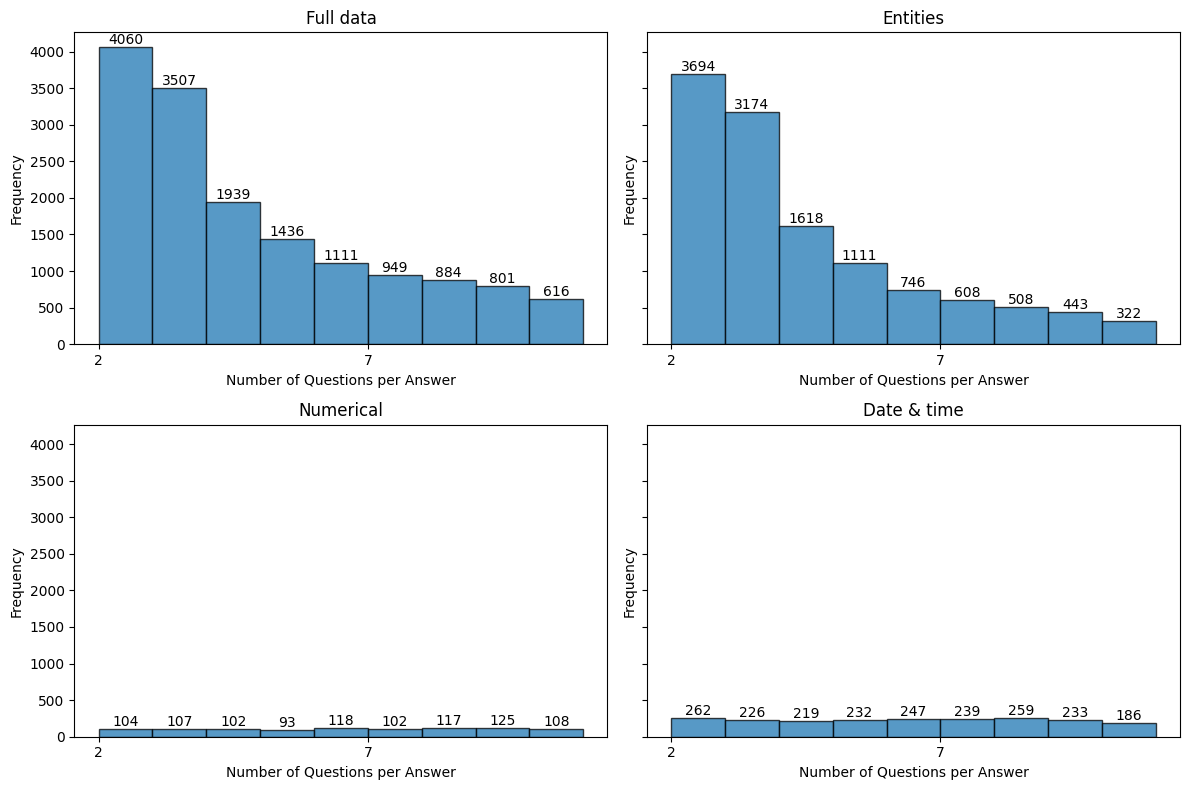

In [431]:
from knowledge_maze.create_dataset.create_reasoning_path import plot_clusters_distribution
plot_clusters_distribution({
    'Full data': reasoning_chains,
    'Entities': entity_reasoning_chains,
    'Numerical': numerical_reasoning_chains,
    'Date & time': date_reasoning_chains
})

In [432]:
from random import choice
# Plot random clusters:
print('=' * 50)
print('Entitity Cluster:')
print('=' * 50)
ent_sample = choice(entity_reasoning_chains)
print(f"Answer: {ent_sample['Answer']}")
print("List of questions:")
for question in ent_sample['Questions']:
    print(f"- {question}")
print('=' * 50)
print('Numerical Cluster:')
print('=' * 50)
ent_sample = choice(numerical_reasoning_chains)
print(f"Answer: {ent_sample['Answer']}")
print("List of questions:")
for question in ent_sample['Questions']:
    print(f"- {question}")
print('=' * 50)
print('Date & time Cluster:')
print('=' * 50)
ent_sample = choice(date_reasoning_chains)
print(f"Answer: {ent_sample['Answer']}")
print("List of questions:")
for question in ent_sample['Questions']:
    print(f"- {question}")
print('=' * 50)

Entitity Cluster:
Answer: Paul Jones
List of questions:
- A circular partner-swapping ballroom dance, named after a 1700s maritime leader, is the?
- Which harmonica-paying frontman of Manfred Man sang on their early hits and later became a successful radio presenter?
- Who presents the Radio 2 Rhythm & Blues Show at 7.00pm every Monday?
Numerical Cluster:
Answer: (11, 20)
List of questions:
- how many secret herbs and spices in kfc
- how many volumes of akatsuki no yona are there
- how many series are there in midsomer murders
- how many episodes are in season 3 of fuller house
- how many episodes of hap and leonard are there
- how many series of family guy is there
- how many times did al ahly win caf
- what age do you get your license in michigan
Date & time Cluster:
Answer: ['full_date', 2008]
List of questions:
- when did angus thongs and perfect snogging made
- when was the large hadron collider first turned on
- when did the corkscrew close at alton towers
- when did the new shap

Answer: Virat Kohli
Questions before filtering:
1. who has scored the most t20 runs for india
2. who is the indian cricket team captain 2018
3. who is the captain of indian cricket team right now
4. who won icc cricketer of the year award
5. who has been named as the cricketer of the year in the icc annual awards
6. which player highest numbers of runs in ipl history
7. who is the captain of india in cricket
8. which indian captain has won the maximum matches against sri lanka
9. who has been wisdens leading cricketer in the world for 2016
10. who scored most runs in t20 for india
11. who is the vice captain of india 2017


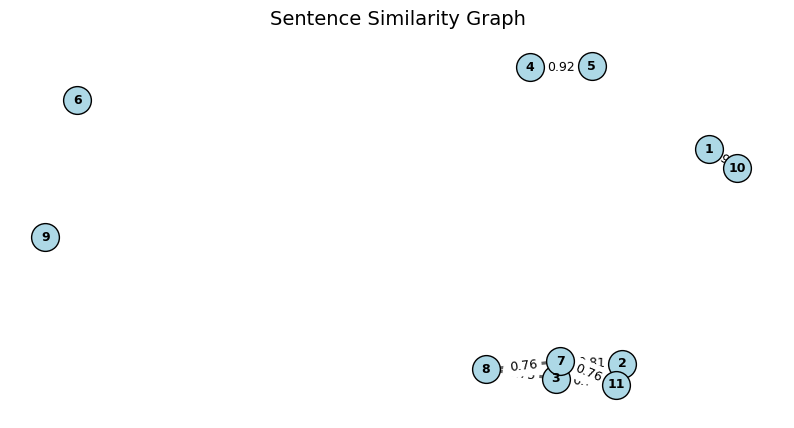

Questions after filtering:
1. who has been named as the cricketer of the year in the icc annual awards
2. which player highest numbers of runs in ipl history
3. which indian captain has won the maximum matches against sri lanka
4. who has been wisdens leading cricketer in the world for 2016
5. who scored most runs in t20 for india
6. who is the vice captain of india 2017


In [80]:
# Plot graph example - (filtering process):
from knowledge_maze.create_dataset.create_reasoning_path import display_random_sample
display_random_sample(ent_clusters, entity_questions_embeddings)

# 4. Structure Data & Generate Counter Answers:

**Dataset Structure:**
```
{
    'ID': '',
    'Question': '',
    'Answer type': '',
    'Answers': {
        'Memory answer': '',
        'Counter answer 1': '',
        'Counter answer 2': '',
        'Distractor answer': ''
    },
    'Reasoning path 1':[
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''}
    ],
    'Reasoning path 2':[
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''}
    ]
    'Distractor paragraphs': []
}
```

In [433]:
from knowledge_maze.create_dataset.create_data import process_data_to_list
structured_entities = await process_data_to_list(entity_reasoning_chains[:100], 'Wikipedia Entity')
structured_numericals = await process_data_to_list(numerical_reasoning_chains[:50], 'Numerical')
structured_dates = await process_data_to_list(date_reasoning_chains[:50], 'Date & Time')
# Merge all data:
knowledge_maze_qa = list(np.concatenate([structured_entities, structured_numericals, structured_dates]))
# Save Dataset:
output_path = f"{REPO_PATH}\data_files\\knowledge_maze_qa.json"
with open(output_path, "w", encoding="utf-8") as out_file:
    json.dump(knowledge_maze_qa, out_file)

100%|██████████████████████████████████████████████████████████████████████████████████| 50/50 [00:02<00:00, 19.16it/s]


In [ ]:
# Load from saved dataset:
knowledge_maze_qa = load_json(f"{REPO_PATH}\data_files\\knowledge_maze_qa.json")

# 5. Generate Paragraphs:

In [404]:
from knowledge_maze.create_dataset.create_data import create_paragraphs

knowledge_maze_paragraphs = await create_paragraphs(knowledge_maze_qa)

# Save Dataset:
output_path = f"{REPO_PATH}\data_files\\knowledge_maze_paragraphs.json"
with open(output_path, "w", encoding="utf-8") as out_file:
    json.dump(knowledge_maze_paragraphs, out_file)

Usage cost: 0.0354$ (Estimated: 0.04$): 100%|████████████████████████████████████████| 370/370 [00:17<00:00, 21.60it/s]


In [ ]:
# Load from saved dataset:
knowledge_maze_paragraphs = load_json(f"{REPO_PATH}\data_files\\knowledge_maze_paragraphs.json")

# TESTING

In [20]:
tqa_dataset = load_json(f"{REPO_PATH}\data_files\extracted_nq.json")
nq_dataset = load_json(f"{REPO_PATH}\data_files\extracted_squad.json")
sqd_dataset = load_json(f"{REPO_PATH}\data_files\extracted_triviaQA.json")
total_samples = tqa_dataset + nq_dataset + sqd_dataset

In [720]:
import re

def word_overlap(sentence1: str, sentence2: str) -> set:
    """
    Computes the overlap of words between two sentences.
    
    Args:
        sentence1 (str): The first sentence.
        sentence2 (str): The second sentence.
    
    Returns:
        set: A set of words that appear in both sentences.
    """
    # Normalize sentences: convert to lowercase and split into words
    words1 = set(re.findall(r'\w+', sentence1.lower()))
    words2 = set(re.findall(r'\w+', sentence2.lower()))
    
    # Compute the intersection
    try:
        return len(words1 & words2) / len(words2)
    except:
        return 0

# Example usage:
sentence_a = "The quick brown fox jumps over the lazy dog."
sentence_b = "A lazy dog sleeps while the quick fox runs."
print(word_overlap(sentence_a, sentence_b))

0.5555555555555556


In [726]:
ans_in_ques = 0
for sample in total_samples:
    # if sample['Answer'] in sample['Question']:
    if word_overlap(sample['Question'], sample['Answer']) == 1.0: # and sample['Answer'] not in sample['Question']:
        ans_in_ques += 1
        # print(f"{sample['Question']} --> {sample['Answer']} --> {word_overlap(sample['Question'], sample['Answer'])}")
print(f"{ans_in_ques}/{len(total_samples)} ({100 * (ans_in_ques / len(total_samples)):.1f})%")

2885/272007 (1.1)%


In [694]:
sntence_1 = 'Question: what is the tallest building in the northern hemisphere? Answer: Burj Khalifa'
sntence_2 = 'Burj Khalifa is the tallest building in the northern hemisphere'
type1 = nlp(sntence_1)
type2 = nlp(sntence_2)

In [703]:
print(type1.ents[0].label_)
print(type2.ents[0].label_)

PERSON
FAC


In [617]:
import random
import torch
aug_ques = []
for sample in total_samples: #random.choices(total_samples, k=5000):
    question_words = ["What", "Who", "When", "Where", "How", "Which"]
    match_count = sum(1 for word in question_words if word.lower() in sample['Question'].lower())
    # Check if exactly one question word is present
    if match_count == 1:
        aug_ques.append({"Question": sample['Question'], "Answer": sample['Answer']})

clust_aug_ques = cluster_wiki_entities(aug_ques)

filt_filt_ques = []
for answer, questions in clust_aug_ques.items():
    for question in questions:
        filt_filt_ques.append(f"Question: {question} Answer: {answer}")

# Load spaCy's Named Entity Recognizer:
# Force GPU usage if available:
if torch.cuda.is_available():
    spacy.require_gpu()
else:
    print("Notice: GPU not available, running on CPU.")
nlp = spacy.load("en_core_web_trf")
extracted_entities_aug = []
for doc in tqdm(nlp.pipe(filt_filt_ques, batch_size=1024), total=len(filt_filt_ques), desc="Extracting Entities"):
    extracted_entities_aug.append([(ent.text, ent.label_) for ent in doc.ents])
data_testest = []
for name, ent in zip(filt_filt_ques, extracted_entities_aug):
    if len(ent) > 0:
        if name.split(' Answer: ')[-1] == ent[-1][0]:
            data_testest.append(
                {
                    "Question": name.split(' Answer: ')[0],
                    "Answer": name.split(' Answer: ')[-1],
                    "Type": ent[-1]
                }
            )
            # print(f"{name.split(' Answer: ')[0]} --> {ent[-1]}")

Extracting Entities: 100%|████████████████████████████████████████████████████| 111842/111842 [06:12<00:00, 300.02it/s]


AttributeError: 'dict' object has no attribute 'split'

In [618]:
data_testest = []
for name, ent in zip(filt_filt_ques, extracted_entities_aug):
    if len(ent) > 0:
        if name.split(' Answer: ')[-1] == ent[-1][0]:
            data_testest.append(
                {
                    "Question": name.split(' Answer: ')[0],
                    "Answer": name.split(' Answer: ')[-1],
                    "Type": ent[-1]
                }
            )
            # print(f"{name.split(' Answer: ')[0]} --> {ent[-1]}")

In [619]:
from collections import defaultdict

def group_by_answer_and_type(data):
    """
    Groups questions based on the same answer and type, combining questions into a list.

    Args:
        data (list[dict]): List of dictionaries with keys "Question", "Answer", and "Type".

    Returns:
        list[dict]: List of grouped dictionaries with the same structure but "Question" as a list.
    """
    grouped_data = defaultdict(lambda: {"Questions": [], "Answer": None, "Type": None})

    for item in data:
        key = (item["Answer"], item["Type"])
        grouped_data[key]["Questions"].append(item["Question"])
        grouped_data[key]["Answer"] = item["Answer"]
        grouped_data[key]["Type"] = item["Type"]

    # Convert defaultdict to a standard list of dictionaries
    result = {}
    for grouped_item in grouped_data.values():
        result[grouped_item["Answer"]] = grouped_item["Questions"]
    # result = [
    #     {"Question": grouped_item["Questions"], "Answer": grouped_item["Answer"], "Type": grouped_item["Type"]}
    #     for grouped_item in grouped_data.values()
    # ]

    return result

In [625]:
grouped_data_testest = group_by_answer_and_type(data_testest)
filt_grouped_data_testest = {}
for answer, questions in grouped_data_testest.items():
    if len(questions) > 1:
        filt_grouped_data_testest[answer] = questions

filt_grouped_data_testest

{'Cyclops': ['Question: In Greek mythology, what is the name for a one-eyed giant?',
  'Question: What creature from Greek mythology has a single eye on the center of its forehead?',
  'Question: In Greek mythology, what sort of creature was Polyphemus?'],
 'Thurgood Marshall': ['Question: Who was the first black Supreme Court justice?',
  'Question: President Lyndon B. Johnson nominated the first African American judge to the US Supreme Court. Who was it?',
  'Question: who was the first african american to serve on the supreme court',
  'Question: who led the team that challenged the separate but equal ruling',
  'Question: who was the first african american supreme court justice',
  'Question: who was the first african american appointed to supreme court'],
 'Kerry': ['Question: Of which Irish county is Tralee the county town?',
  'Question: In which Irish county is Dingle Bay'],
 '2256': ['Question: when does the star trek discovery take place',
  'Question: where does star trek di

In [627]:
test_reasoning_chains = await create_paths(filt_grouped_data_testest)

Generating question embeddings: 100%|██████████████████████████████████████████████████| 39/39 [02:05<00:00,  3.22s/it]
Creating similarity graphs and filtering questions: 100%|██████████████████████| 10240/10240 [00:09<00:00, 1028.43it/s]
Splitting large clusters: 100%|██████████████████████████████████████████████| 10240/10240 [00:00<00:00, 696884.25it/s]


In [628]:
structured_testtest = await process_data_to_list(test_reasoning_chains[:100], 'Wikipedia Entity')

Usage cost: 0.0032$ (Estimated: 0.00$): 100%|██████████████████████████████████████████| 75/75 [00:05<00:00, 13.81it/s]


In [661]:
from knowledge_maze.create_dataset.data_annotation import display_qa_sample
display_qa_sample(random.choice(structured_testtest))

ID: 11e3ccff-9b08-4702-b431-5e5f71604717
Type: Wikipedia Entity
Question: Question: "The ""Missouri Compromise"" allowed which state to join the USA in 1820 to
          balance the admission of Missouri?"
Original answer from dataset: None

Answers:
- Maine (Memory answer)
- Vermont (Counter answer 1)
- New Hampshire (Counter answer 2)
- Massachusetts (Distractor answer)

Sub-questions path 1:
 1. Question: "The ""Missouri Compromise"" allowed which state to join the USA in 1820 to
    balance the admission of Missouri?" --> None
 2. Question: In what U.S. state was Stephen King born? --> None
 3. Question: The town of Purgatory is in which US state? --> None

Sub-questions path 2:
 1. Question: "The ""Missouri Compromise"" allowed which state to join the USA in 1820 to
    balance the admission of Missouri?" --> None
 2. Question: The northernmost USA state on the eastern seaboard lies partly north of its
    neighbouring Canadian territory. Which is the state? --> None
 3. Question:

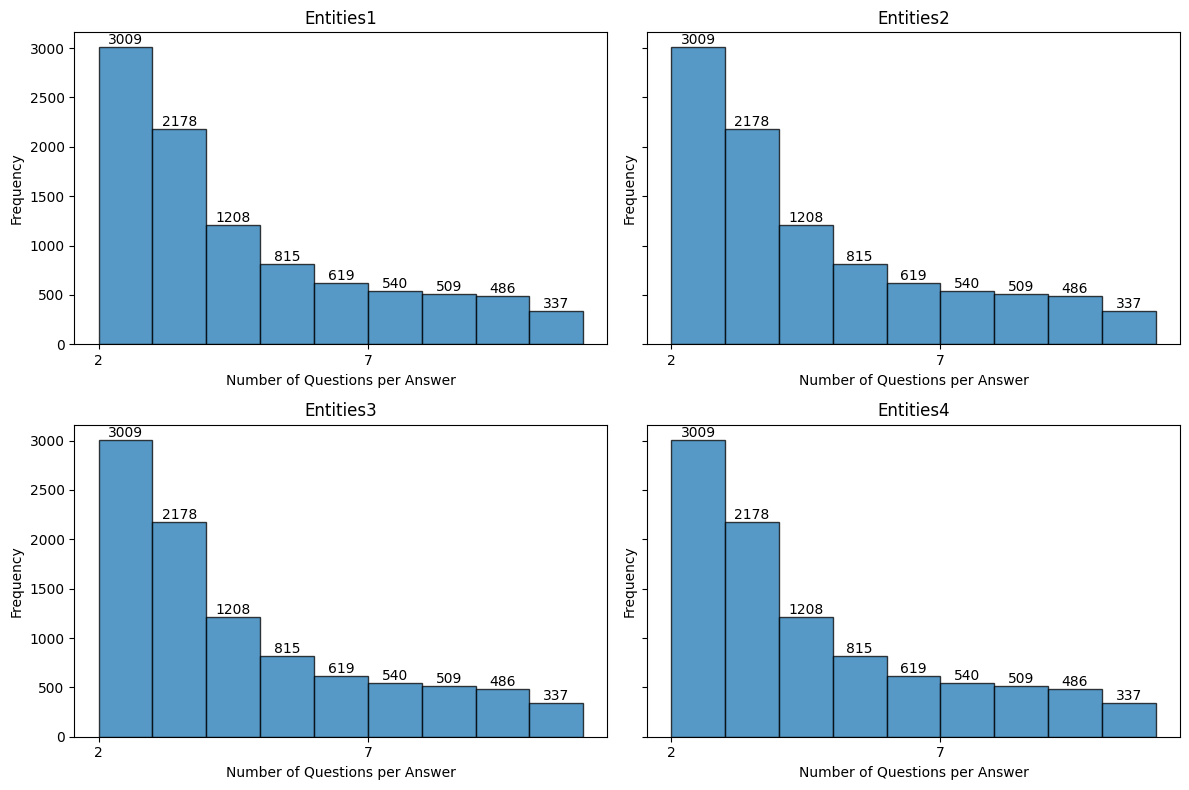

In [649]:
from knowledge_maze.create_dataset.create_reasoning_path import plot_clusters_distribution

lenths_testest = [len(sample["Questions"]) for sample in test_reasoning_chains]
plot_clusters_distribution({
    'Entities1': test_reasoning_chains,
    'Entities2': test_reasoning_chains,
    'Entities3': test_reasoning_chains,
    'Entities4': test_reasoning_chains,
})

In [763]:
cccount = 0
ddcount = 0
list_of_answers = list(set([sample['Answer'] for sample in data_testest]))# [400:700] # ['British', 'French', 'American']
for answer in tqdm(list_of_answers):
    sample_answer_types = []
    for sample in data_testest:
        if sample['Answer'] == answer:
            sample_answer_types.append(sample['Type'][1])
    if len(list(set(sample_answer_types))) > 1:
        cccount += 1
        ddcount += len(sample_answer_types)
        # print('=' * 100)
        # print(f"{answer}: {list(set(sample_answer_types))}")
        # for sample in data_testest:
        #     if sample['Answer']== answer:
        #         print(f"{sample['Question']} --> {sample['Answer']} ({sample['Type'][1]})")
print(f"{cccount} / {len(list_of_answers)} ({100 * cccount / len(list_of_answers):.1f}%)")
print(f"{ddcount} / {len(data_testest)} ({100 * ddcount / len(data_testest):.1f}%)")

100%|███████████████████████████████████████████████████████████████████████████| 11459/11459 [01:39<00:00, 115.46it/s]

1492 / 11459 (13.0%)
13512 / 91304 (14.8%)


In [691]:
types_examples = []
for sample in data_testest:
    if sample['Type'][1] == 'FAC':
        types_examples.append(sample['Answer'])
        if sample['Answer']== "Munich":
            print(f"{sample['Question']} --> {sample['Answer']}")
print(list(set(types_examples)))

Question: Where did Queen record their 1982 album?  --> Munich
['Gloucester Cathedral', 'Nationals Park', 'Eighth', 'Royal Oak', 'Number One Observatory Circle', 'Quality Street', 'M4', 'The Crucible', 'Square', 'Kew Gardens', 'Longleat', 'Benghazi', 'Skye', 'Dolby Theatre', 'Speedway', 'Vatican City', 'Hanover', 'Cherbourg-Octeville', 'Monaco', 'Arc de Triomphe', 'Palace of Westminster', 'Buckingham Palace', 'Vine Street', 'Central', 'Central Park', 'Yankee Stadium', 'Yellowstone National Park', 'East High School', 'Berkeley', 'AT&T Stadium', 'Lexington', 'Palace of Versailles', 'Welland Canal', 'Bastille', 'Dunedin Stadium', 'Augusta', 'Sunset Boulevard', 'Shangri-La', 'Castle Howard', 'Piccadilly', 'St. Moritz', 'Wembley Stadium', 'Kensington Gardens', 'Port of Spain', 'Gettysburg', 'Bridge', 'Shamrock', "St. John's", 'Balmoral Castle', 'Louvre', 'Lodge', 'Charles de Gaulle Airport', 'Queenstown', 'Telescope', 'Panama Canal', 'Hogwarts', 'Riverside Drive', 'Bramall Lane', 'Vatican I

In [606]:
def count_how_many(dataset):
    person_answers = []
    """
    Counts how many questions contain exactly one of the specified question words.

    Args:
        dataset (list[dict]): Dataset containing questions.

    Returns:
        int: Number of questions containing exactly one question word.
    """
    question_words = ["What", "Who", "When", "Where", "How", "Which"]
    count_question_words = 0

    # Iterate over the dataset
    for sample in dataset:
        # Count how many question words appear in the question
        match_count = sum(1 for word in question_words if word.lower() in sample['Question'].lower())
        # Check if exactly one question word is present
        if match_count == 1:
            count_question_words += 1
            # if "where" in sample['Question'].lower():
            #    print(f"{sample['Question']} --> {sample['Answer']}")
            person_answers.append(sample['Answer'])

    return count_question_words, person_answers


# Print the count and the total number of samples
rel_count = count_how_many(tqa_dataset)[0] + count_how_many(nq_dataset)[0] + count_how_many(sqd_dataset)[0]
tot_count = len(sqd_dataset)+ len(nq_dataset) + len(sqd_dataset)
print(f"{rel_count} / {tot_count} ({100 * (rel_count / tot_count):.1f}%)")

245854 / 280568 (87.6%)


In [607]:
person_answers = count_how_many(tqa_dataset)[1] + count_how_many(nq_dataset)[1] + count_how_many(sqd_dataset)[1]

In [608]:
import matplotlib.pyplot as plt
from collections import Counter

def create_name_frequency_histogram_and_extract(names):
    """
    Creates a histogram of name frequencies and returns a set of names that appear more than 2 times.

    Args:
        names (list[str]): A list of names.

    Returns:
        set: A set of names that appear more than 2 times.
    """
    # Count the frequency of each name in the list
    name_counts = Counter(names)
    
    # Count how many names have each frequency (range 0-100)
    frequency_counts = Counter(name_counts.values())
    
    # Prepare data for the histogram (x-axis: frequency, y-axis: count of names with that frequency)
    x_values = range(2, 25)  # Frequencies from 1 to 100
    y_values = [frequency_counts.get(i, 0) for i in x_values]  # Get the count for each frequency, default to 0
    
    # Plot the histogram
    plt.figure(figsize=(10, 6))
    plt.bar(x_values, y_values, color='skyblue', edgecolor='black')
    plt.title('Name Frequency Histogram', fontsize=16)
    plt.xlabel('Frequency of Names', fontsize=14)
    plt.ylabel('Number of Names', fontsize=14)
    plt.xticks(range(2, 25, 5))  # Adjust x-axis ticks for better readability
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()
    
    # Extract names that appear more than 2 times
    names_more_than_2 = {name for name, count in name_counts.items() if count > 2}
    
    return names_more_than_2

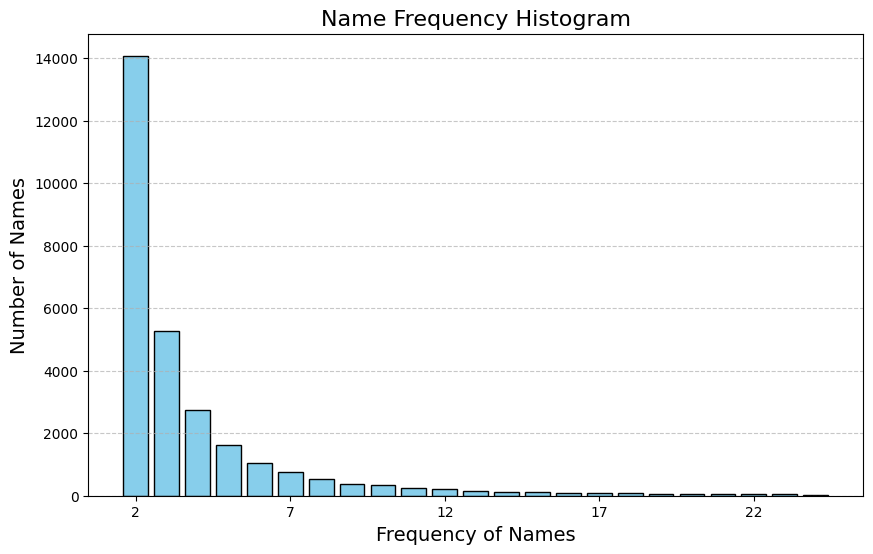

In [609]:
filt_names = create_name_frequency_histogram_and_extract(person_answers)

In [610]:
import spacy

# Load spaCy's Named Entity Recognizer:
nlp = spacy.load("en_core_web_trf")
extracted_entities = []
for doc in tqdm(nlp.pipe(filt_names, batch_size=1024), total=len(filt_names), desc="Extracting Entities"):
    extracted_entities.append([(ent.text, ent.label_) for ent in doc.ents])
for name, ent in zip(filt_names, extracted_entities):
    print(f"{name} --> {ent}")

Extracting Entities: 100%|██████████████████████████████████████████████████████| 14667/14667 [02:09<00:00, 113.68it/s]

horses --> []
James A. Garfield --> [('James A. Garfield', 'PERSON')]
Matthew David Lewis --> [('Matthew David Lewis', 'PERSON')]
Battlestar Galactica --> [('Battlestar Galactica', 'WORK_OF_ART')]
the fourth season --> [('fourth', 'ORDINAL')]
KAZZ (AM) --> [('KAZZ', 'PERSON')]
Jonah Hill --> [('Jonah Hill', 'PERSON')]
Anthony Newley --> [('Anthony Newley', 'PERSON')]
Zhu Yuanzhang --> [('Zhu Yuanzhang', 'PERSON')]
1990s --> [('1990s', 'DATE')]
Eric Morecambe --> [('Eric Morecambe', 'PERSON')]
Terry Gilliam --> [('Terry Gilliam', 'PERSON')]
Jean Sibelius --> [('Jean Sibelius', 'PERSON')]
East India Company --> [('East India Company', 'GPE')]
Sevastopol --> [('Sevastopol', 'GPE')]
Cyclops --> []
Thurgood Marshall --> [('Thurgood Marshall', 'PERSON')]
Mumford & Sons --> [('Mumford & Sons', 'ORG')]
Jonathan Breck --> [('Jonathan Breck', 'PERSON')]
Sean McVay --> [('Sean McVay', 'PERSON')]
Kerry --> [('Kerry', 'PERSON')]
Ronald N. Perlman --> [('Ronald N. Perlman', 'PERSON')]
K.K. Venugopal

In [611]:
for name, ent in zip(filt_names, extracted_entities):
    if any(char.isupper() for char in name):
        print(f"{name} --> {ent}")

James A. Garfield --> [('James A. Garfield', 'PERSON')]
Matthew David Lewis --> [('Matthew David Lewis', 'PERSON')]
Battlestar Galactica --> [('Battlestar Galactica', 'WORK_OF_ART')]
KAZZ (AM) --> [('KAZZ', 'PERSON')]
Jonah Hill --> [('Jonah Hill', 'PERSON')]
Anthony Newley --> [('Anthony Newley', 'PERSON')]
Zhu Yuanzhang --> [('Zhu Yuanzhang', 'PERSON')]
Eric Morecambe --> [('Eric Morecambe', 'PERSON')]
Terry Gilliam --> [('Terry Gilliam', 'PERSON')]
Jean Sibelius --> [('Jean Sibelius', 'PERSON')]
East India Company --> [('East India Company', 'GPE')]
Sevastopol --> [('Sevastopol', 'GPE')]
Cyclops --> []
Thurgood Marshall --> [('Thurgood Marshall', 'PERSON')]
Mumford & Sons --> [('Mumford & Sons', 'ORG')]
Jonathan Breck --> [('Jonathan Breck', 'PERSON')]
Sean McVay --> [('Sean McVay', 'PERSON')]
Kerry --> [('Kerry', 'PERSON')]
Ronald N. Perlman --> [('Ronald N. Perlman', 'PERSON')]
K.K. Venugopal --> [('K.K. Venugopal', 'PERSON')]
Hawthorn --> [('Hawthorn', 'PERSON')]
X --> []
John St

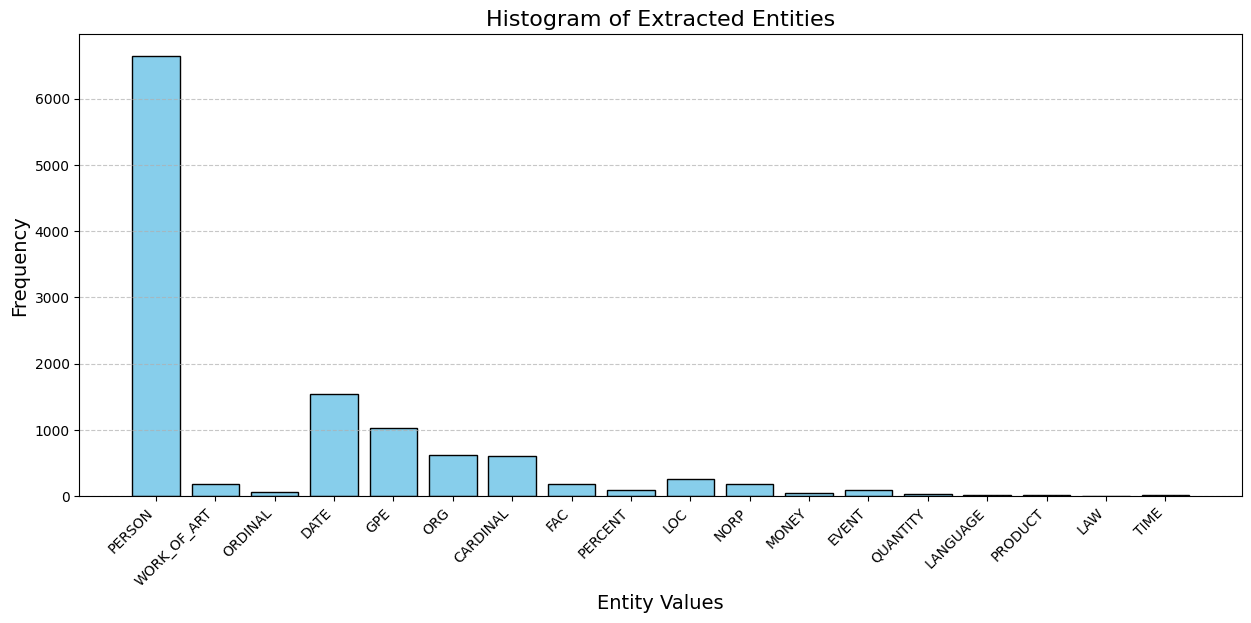

In [613]:
import matplotlib.pyplot as plt
from collections import Counter

# Prepare your data
data = [ent[0][1] for ent in extracted_entities if len(ent) >= 1]

# Count the frequencies of the data
frequency_counts = Counter(data)

# Extract the unique labels and their frequencies
x_labels = list(frequency_counts.keys())
y_values = list(frequency_counts.values())

# Create the histogram
plt.figure(figsize=(15, 6))
plt.bar(x_labels, y_values, width=0.8, color='skyblue', edgecolor='black')

# Customize x-axis labels to make them diagonal and center them
plt.xticks(rotation=45, ha='right', fontsize=10)  # Rotate labels diagonally
plt.gca().set_xticks(range(len(x_labels)))  # Ensure labels align with their bars
plt.gca().set_xticklabels(x_labels)  # Set custom x-axis labels

# Add labels, title, and grid
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.title('Histogram of Extracted Entities', fontsize=16)
plt.xlabel('Entity Values', fontsize=14)
plt.ylabel('Frequency', fontsize=14)

# Show the plot
plt.show()

In [758]:
def transform_qa(sample):
    question = sample['Question']
    answer = sample['Answer']
    w_words = ['who', 'what', 'which', 'where']
    match_count = sum(1 for word in w_words if word.lower() in question.lower())
    # Check if exactly one question word is present
    if match_count == 1:
        if 'who' in question.lower():
            return re.sub('who', answer, question.lower())
        if 'what' in question.lower():
            return re.sub('what', answer, question.lower())
        if 'which' in question.lower():
            return re.sub('which', f"{answer} is the", question.lower())
        if 'where' in question.lower():
            return re.sub('where', answer, question.lower())
    else:
        return None
    return sentence

In [739]:
rr_count = 0
for sample in total_samples:
    question = sample['Question']
    answer = sample['Answer']
    w_words = ['who', 'what', 'where', 'when', 'how much', 'how many', 'which']
    match_count = sum(1 for word in w_words if word.lower() in question.lower())
    if match_count == 1:
        if 'how much' in question: #question.split(' ')[0] in w_words:
            rr_count += 1
            print(question)
print(f"{rr_count}/{len(total_samples)}")

In 1903 Congress imposed a tax of how much per head for immigrants entering the country?
In dollars, how much did the USA pay Russia for Alaskan territory in 1867?
In dollars, how much did the 1997 film Titanic gross in its opening weekend in America?
In UK Monopoly, how much money does each player have at the start of the game?
In British decimal coinage, how much would a guinea be worth?
In British currency slang, how much is a ‘Pony’ worth?
A sovereign is a British gold coin worth how much in sterling?
(Approximately) how much does a cubic foot of gold weigh?
In British currency slang, how much is a 'Monkey' worth?
According to popular medical opinion (at 2011) how much sleep on average is best per night for optimum adult health?
Compared to playing the string open, placing a finger behind the 12th fret on a guitar finger board raises the note by how much?
Approximately how much of the water on earth is fresh water?
If after spending 10% of your money, you have $180 left, how much d

In [759]:
ct = 0
for sample in total_samples[:100]:
    sentence = transform_qa(sample)
    if sentence:
        print(f"{sentence} --> {sample['Answer']}")
        ct += 1
print(ct)

Harry S. Truman was president when the first peanuts cartoon was published? --> Harry S. Truman
Sinclair Lewis is the american-born sinclair won the nobel prize for literature in 1930? --> Sinclair Lewis
York in england was dame judi dench born? --> York
in 30s is the decade did billboard magazine first publish and american hit chart? --> 30s
from Portugal is the country did angola achieve independence in 1975? --> Portugal
Chicago is the city does david soul come from? --> Chicago
Chicago Bears won super bowl xx? --> Chicago Bears
Norway is the was the first european country to abolish capital punishment? --> Norway
in Japan is the country did he widespread use of isdn begin in 1988? --> Japan
Walter is bruce willis' real first name? --> Walter
Golding is the william wrote the novel lord of the flies? --> Golding
Windscreen wiper is the innovation for the car was developed by prince henry of prussia in 1911? --> Windscreen wiper
to ten thousand square miles 121,364 square miles it the

In [25]:
import matplotlib.pyplot as plt

def generate_question_pie_chart(data):
    """
    Creates a pie chart showing the distribution of questions containing specific keywords,
    including both the percentage and count in the labels.

    Args:
        data (list[dict]): List of dictionaries with keys 'question' and 'answer'.

    Returns:
        None
    """
    # Define keywords to search for
    keywords = ['who', 'what', 'where', 'when', 'how much', 'how many', 'which', 'how old']
    keyword_counts = {word: 0 for word in keywords}
    keyword_counts['else'] = 0  # Category for questions not matching any keyword
    
    # Count occurrences
    for entry in data:
        question = entry['Question'].lower()
        matched = False
        for word in keywords:
            if word in question:
                keyword_counts[word] += 1
                matched = True
                break
        if not matched:
            keyword_counts['else'] += 1
    
    # Prepare data for the pie chart
    labels = list(keyword_counts.keys())
    sizes = list(keyword_counts.values())
    
    # Format labels with both percentage and count
    def format_label(pct, all_values):
        absolute = int(round(pct / 100.0 * sum(all_values)))
        return f"{pct:.1f}% ({absolute})"
    
    plt.figure(figsize=(8, 8))
    wedges, texts, autotexts = plt.pie(
        sizes, 
        labels=labels, 
        autopct=lambda pct: format_label(pct, sizes), 
        startangle=90, 
        colors=plt.cm.Paired.colors
    )
    
    # Customize label and title styles
    plt.setp(autotexts, size=10, weight="bold")
    plt.title("Distribution of Question Keywords", fontsize=16)
    plt.show()

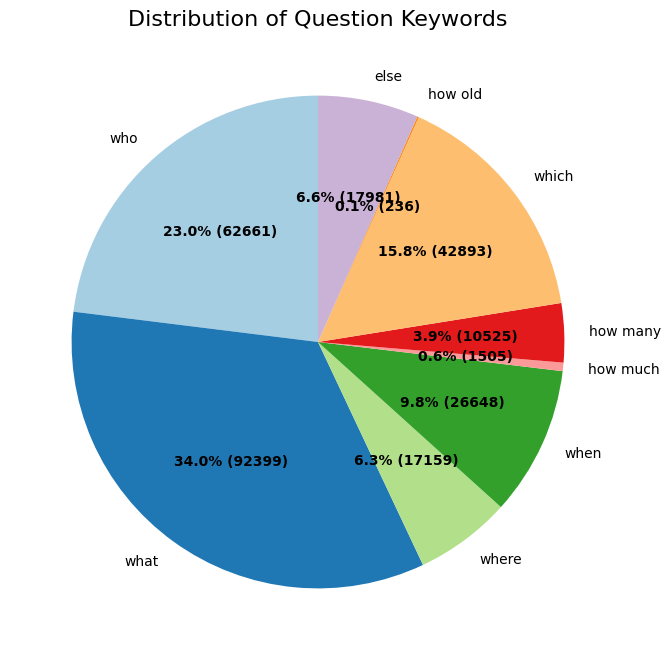

In [26]:
generate_question_pie_chart(total_samples)

In [33]:
aaacount = 0
for sample in total_samples[:1000]:
    if 'when' in sample['Question'].lower():
        print(f"{sample['Question']} --> {sample['Answer']}")
    # if '%' in sample['Answer']:
    #     aaacount += 1
    #     # print(f"{sample['Question']} --> {sample['Answer']}")
print(f"{aaacount}/{len(total_samples)} ({100*aaacount/len(total_samples):.1f})")

Who was President when the first Peanuts cartoon was published? --> Harry S. Truman
When did the founder of Jehovah's Witnesses say the world would end? --> 1914
Who became US Vice President when Spiro Agnew resigned? --> Gerald Ford
Who was British Prime Minister when World War II broke out? --> Neville Chamberlain
How old was Sean Connery when he played 46-year old Harrison Ford's father in Indiana Jones & The Last Crusade? --> 58
How old was Ronald Reagan when he became US President? --> 69
How old was Elizabeth Taylor when she appeared in National Velvet? --> 82,751 square miles
Who took the assumed name Sebastian Melmoth when living in Paris? --> Oscar Wilde
When was the Scrabble World championship first held? --> 1991
Daryl Dragon used which name when he formed a 70s duo? --> Captain
When she died how old was Karen Carpenter? --> 32
What was the USA's biggest attack of the Vietnam War when it took place in February 1967? --> Operation Junction City
Who was the defending champion 

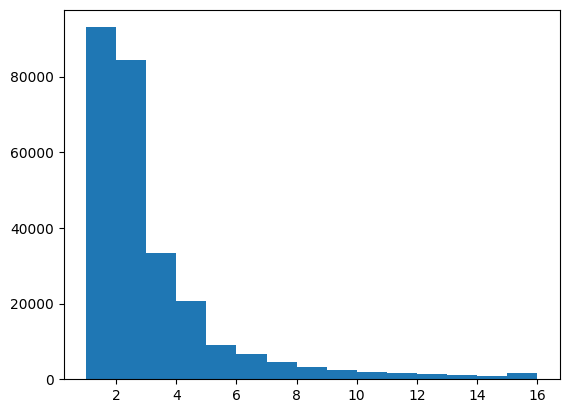

In [48]:
answer_lengths = [len(sample['Answer'].split(' ')) for sample in total_samples]
plt.hist(answer_lengths, bins=[1,2,3,4,5,6,7,8,9,10, 11, 12, 13,14,15,16])
plt.show()

# Test 2:

In [18]:
import numpy as np
import random
from sklearn.metrics.pairwise import cosine_similarity
from typing import Dict, List, Tuple # For type hinting

def group_questions_by_similarity(
    question_embeddings: Dict[str, np.ndarray],
    min_group_size: int,
    max_group_size: int
) -> List[List[str]]:
    """
    Groups questions based on embedding similarity into subgroups of randomized size.

    Starts with a random question, finds its most similar neighbors iteratively
    until a random target size (between min/max) is reached for the group,
    or no more questions remain. Repeats until all questions are grouped.

    Args:
        question_embeddings: A dictionary where keys are question strings and
                             values are their corresponding embedding vectors
                             (e.g., NumPy arrays or lists of floats).
        min_group_size: The minimum desired size for each subgroup.
        max_group_size: The maximum desired size for each subgroup.

    Returns:
        A list of lists, where each inner list contains question strings
        representing a semantically grouped subgroup. The last group might be
        smaller than min_group_size if fewer questions remain.

    Raises:
        ValueError: If input dictionary is empty, min/max sizes are invalid,
                    or embeddings have inconsistent dimensions.
    """

    # --- Input Validation ---
    if not question_embeddings:
        raise ValueError("Input 'question_embeddings' dictionary cannot be empty.")
    if not isinstance(min_group_size, int) or not isinstance(max_group_size, int):
        raise ValueError("min_group_size and max_group_size must be integers.")
    if min_group_size < 1:
        raise ValueError("min_group_size must be at least 1.")
    if min_group_size > max_group_size:
        raise ValueError("min_group_size cannot be greater than max_group_size.")

    # --- Prepare Data ---
    questions = list(question_embeddings.keys())
    try:
        # Ensure all embeddings are NumPy arrays and check dimensions
        embeddings = np.array([np.asarray(emb.cpu(), dtype=float) for emb in question_embeddings.values()])
        if embeddings.ndim != 2:
             raise ValueError("Embeddings must form a 2D array.")
        initial_dim = embeddings.shape[1]
        if initial_dim == 0:
            raise ValueError("Embeddings cannot have zero dimension.")
    except Exception as e:
        raise ValueError(f"Error processing embeddings: {e}. Ensure they are valid numerical lists/arrays.") from e

    num_questions = len(questions)
    remaining_indices = list(range(num_questions)) # Indices corresponding to 'questions' list
    random.shuffle(remaining_indices) # Start grouping from random questions

    all_groups = []

    print(f"Starting grouping for {num_questions} questions...")

    while remaining_indices:
        # --- Start a New Group ---
        # Pick a seed question index from the remaining ones
        seed_index = remaining_indices.pop(0)
        current_group_indices = [seed_index]
        target_size = random.randint(min_group_size, max_group_size)
        print(f"  Starting new group with seed '{questions[seed_index][:50]}...' (Target size: {target_size})")

        # --- Iteratively Add Similar Questions ---
        while len(current_group_indices) < target_size and remaining_indices:
            # Calculate the centroid (average embedding) of the current group
            current_group_embeddings = embeddings[current_group_indices]
            group_centroid = np.mean(current_group_embeddings, axis=0, keepdims=True) # Keep as 2D row vector

            # Get embeddings of the questions still remaining
            remaining_embeddings = embeddings[remaining_indices]

            # Calculate cosine similarity between the centroid and remaining embeddings
            similarities = cosine_similarity(group_centroid, remaining_embeddings)[0] # Get the 1D array of similarities

            # Find the index within 'remaining_indices' of the most similar question
            most_similar_local_idx = np.argmax(similarities)
            # Convert local index back to the original index
            most_similar_original_idx = remaining_indices[most_similar_local_idx]

            # Add the most similar question to the group
            current_group_indices.append(most_similar_original_idx)
            # Remove it from the list of remaining indices
            remaining_indices.pop(most_similar_local_idx) # Remove by local index before list changes

            # Optional: Print progress
            # print(f"    Added '{questions[most_similar_original_idx][:50]}...' (Similarity: {similarities[most_similar_local_idx]:.4f})")


        # --- Finalize Group ---
        # Convert indices back to question strings
        current_group_questions = [questions[i] for i in current_group_indices]
        all_groups.append(current_group_questions)
        print(f"  Finalized group with {len(current_group_questions)} questions.")

    print(f"Grouping complete. Created {len(all_groups)} groups.")
    return all_groups

# --- Example Usage ---
if __name__ == '__main__':
    # Create some dummy data (replace with your actual embeddings)
    # In a real scenario, these embeddings would come from a model like Sentence-BERT etc.
    dummy_embeddings = {
        "What is the capital of France?": np.array([0.1, 0.9, 0.1]),
        "Where is Paris located?": np.array([0.15, 0.85, 0.12]),
        "Tell me about the Eiffel Tower": np.array([0.2, 0.8, 0.15]),

        "How does photosynthesis work?": np.array([0.9, 0.1, 0.1]),
        "What do plants need to grow?": np.array([0.85, 0.15, 0.12]),

        "Who wrote Hamlet?": np.array([0.1, 0.1, 0.9]),
        "What are Shakespeare's famous plays?": np.array([0.15, 0.12, 0.85]),
        "Summary of Romeo and Juliet": np.array([0.1, 0.15, 0.92]),
        "About Shakespeare's life": np.array([0.2, 0.1, 0.78]),

        "Explain black holes": np.array([0.5, 0.5, 0.5]),
        "What is general relativity?": np.array([0.45, 0.55, 0.52]),
    }

    min_size = 2
    max_size = 4

    try:
        grouped_questions = group_questions_by_similarity(dummy_embeddings, min_size, max_size)

        print("\n--- Resulting Groups ---")
        for i, group in enumerate(grouped_questions):
            print(f"\nGroup {i+1} (Size: {len(group)}):")
            for q in group:
                print(f"  - {q}")

        # Verify total questions
        total_grouped = sum(len(g) for g in grouped_questions)
        print(f"\nTotal questions in input: {len(dummy_embeddings)}")
        print(f"Total questions grouped: {total_grouped}")
        assert total_grouped == len(dummy_embeddings)

    except ValueError as e:
        print(f"\nError during grouping: {e}")


Error during grouping: Error processing embeddings: 'numpy.ndarray' object has no attribute 'cpu'. Ensure they are valid numerical lists/arrays.


In [16]:
from knowledge_maze.create_dataset.create_reasoning_path import generate_question_embeddings

questions_embeddings = generate_question_embeddings(num_clusters, batch_size=2048)

Generating question embeddings: 100%|████████████████████████████████████████████████████| 6/6 [00:17<00:00,  2.93s/it]


In [19]:
min_size = 3
max_size = 8

try:
    grouped_questions = group_questions_by_similarity(questions_embeddings, min_size, max_size)

    print("\n--- Resulting Groups ---")
    for i, group in enumerate(grouped_questions):
        print(f"\nGroup {i+1} (Size: {len(group)}):")
        for q in group:
            print(f"  - {q}")

    # Verify total questions
    total_grouped = sum(len(g) for g in grouped_questions)
    print(f"\nTotal questions in input: {len(dummy_embeddings)}")
    print(f"Total questions grouped: {total_grouped}")
    assert total_grouped == len(dummy_embeddings)

except ValueError as e:
    print(f"\nError during grouping: {e}")

Starting grouping for 11694 questions...
  Starting new group with seed 'how many teams qualify for the world cup from conc...' (Target size: 8)
  Finalized group with 8 questions.
  Starting new group with seed 'How many Hindu temples exist in London?...' (Target size: 6)
  Finalized group with 6 questions.
  Starting new group with seed 'the upsc consists of how many members besides the ...' (Target size: 5)
  Finalized group with 5 questions.
  Starting new group with seed 'how many episodes are there in naruto shipuden...' (Target size: 4)
  Finalized group with 4 questions.
  Starting new group with seed 'how many times has the us declare war...' (Target size: 5)
  Finalized group with 5 questions.
  Starting new group with seed 'How many copies of On the Origin of Species were c...' (Target size: 7)
  Finalized group with 7 questions.
  Starting new group with seed 'In days, what is the average gestation period of a...' (Target size: 5)
  Finalized group with 5 questions.
  Start

AssertionError: 

Filtering WH questions: 100%|████████████████████████████████████████████████| 10000/10000 [00:00<00:00, 262952.58it/s]


9304 out of 10000 samples have passed (93.0%).


Filtering self containing questions: 100%|██████████████████████████████████████| 9304/9304 [00:00<00:00, 87228.98it/s]


9166 out of 9304 samples have passed (98.5%).


Filtering out long questions: 100%|███████████████████████████████████████████| 9166/9166 [00:00<00:00, 1424099.51it/s]


...

377 numerical samples found (4.1%).


Extracting date & time samples: 100%|██████████████████████████████████████████| 9160/9160 [00:00<00:00, 520685.55it/s]


66 date & time samples found (0.7%).


Extracting rest of the relevant samples: 100%|████████████████████████████████| 9160/9160 [00:00<00:00, 2582845.35it/s]


5894 relevant samples found (64.3%).
Extracting and counting types...
Found 14 unique types from 6337 valid items.
Generating pie chart...


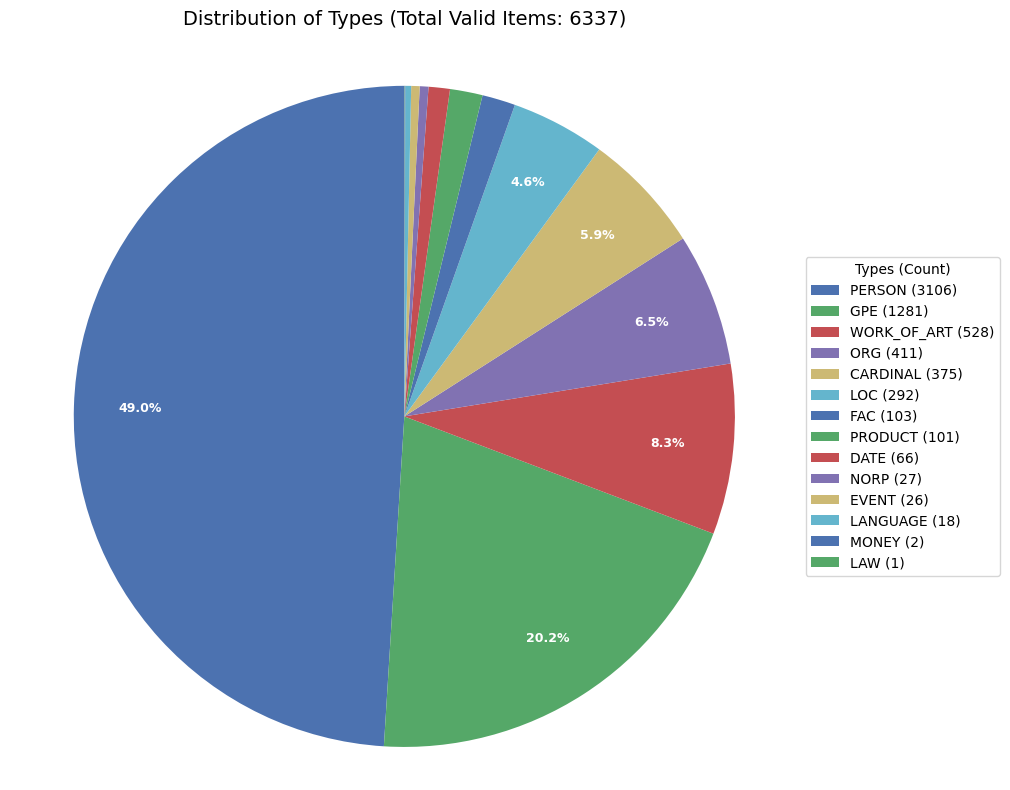

In [133]:
from knowledge_maze.create_dataset.preprocess import preprocess

fi = preprocess(total_samples[:10000])

In [117]:
gdsfsdkjfhlsdjkh = 0

for sample in total_samples:
    if any([word in sample['Question'].lower() for word in ['when', 'what year', 'what month', 'what day', 'the date']]):
       gdsfsdkjfhlsdjkh += 1
       # print(f"{sample['Question']} --> {sample['Answer']}")

print(gdsfsdkjfhlsdjkh)

33452
